# Final baseline: where it works and where it fails

An analysis of the reference baseline (`models.final_baseline`, `docs/final_baseline.md`) on
the held-out eval year, 2025-10-20 → 2026-10-20. It covers the 1,448 forecast runs, one every
6 hours, each 72 hours long. The question is **where the model does well and where it fails,
especially when no CME is involved**: the ambient solar wind of slow wind and high-speed streams
from coronal holes. That is most of the year, and the part a speed-history model should handle.

0. **Forecasts and scores**: the final baseline against persistence and the previous best baseline (rolling 27-day recurrence).
1. **CMEs, shocks and stream arrivals**: identified from the in-situ data, and cross-checked against the SOHO/LASCO CME catalogue.
2. **Performance by regime**: each run labelled by what the wind did during its 72 hours, with a check that the no-CME set is free of CMEs.
3. **No-CME failures**:
   - bias and level;
   - stream arrivals;
   - when the previous rotation is a poor guide;
   - CME echoes;
   - the worst runs.
4. **Findings.**

**Conventions:**
- **Residual** = actual − forecast, so a positive residual means the model under-predicted.
- **Ratio** = a run's TIMSE for the final baseline divided by persistence's for the same run. Below 1, the final baseline wins.
- **Runs:** "per-run" scores treat each 72-hour run on its own, as the platform scores each submission.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from feature_engineering.recurrence import targets
from models.final_baseline import FinalBaseline, run_timse_weights
from training import solar_wind_events as ev
from training.baselines import ALL
from training.datasets import EVAL_END, TRAIN_END, load_hourly
from training.evaluate import HORIZON, forecast_times, run_forecasts, run_timse
from training.metrics import timse

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

MODELS = ["final_baseline", "recurrence_27d_rolling", "persistence"]
STYLE = {
    "final_baseline": {"color": "#2a78d6", "lw": 1.8},
    "recurrence_27d_rolling": {"color": "#eb6834", "lw": 1.3},
    "persistence": {"color": "#8a8984", "lw": 1.5, "ls": (0, (1, 1.5))},
}
REGIME_COLORS = {
    "CME": "#e34948", "possible CME": "#e87ba4", "stream arrival": "#eda100",
    "fast stream": "#6250d6", "slow wind": "#1baf7a", "intermediate": "#52514e",
}
CME_SPAN = {"color": "#e34948", "alpha": 0.18, "lw": 0}
POSSIBLE_SPAN = {"color": "#e87ba4", "alpha": 0.18, "lw": 0}
ROTATION = 27 * 24


def model_legend(fig, extra=()):
    handles = [Line2D([], [], **STYLE[m]) for m in MODELS]
    labels = list(MODELS)
    for handle, label in extra:
        handles.append(handle)
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncol=len(handles), frameon=False, fontsize=9)


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x)

## 0. Forecasts and scores

The final baseline is loaded from the shipped asset (fitted on the training years only) and
run walk-forward over every eval `t0`, using the hours before `t0`. The references go through the
eval harness (`training.evaluate.run_forecasts`).

In [2]:
series = load_hourly()
values = series.to_numpy()
model = FinalBaseline.load()
t0s = forecast_times()
pos = series.index.get_indexer(t0s)

forecasts = {"final_baseline": model.forecast(values, pos)}
# the walk-forward path is the live predict() path, checked here on one run
assert np.allclose(model.predict(series.iloc[: pos[700]]), forecasts["final_baseline"][700])
for name in MODELS[1:]:
    _, forecasts[name], harness_actual = run_forecasts(ALL[name]())
actual = targets(values, pos)
assert np.array_equal(actual, harness_actual, equal_nan=True)

residuals = {m: actual - f for m, f in forecasts.items()}
run_scores = pd.DataFrame({m: run_timse(forecasts[m], actual) for m in MODELS}, index=t0s)
ratio = run_scores["final_baseline"] / run_scores["persistence"]
ratio_rec = run_scores["final_baseline"] / run_scores["recurrence_27d_rolling"]

overall = pd.DataFrame({
    m: {
        "pooled TIMSE": timse(actual, forecasts[m]),
        "per-run mean": run_scores[m].mean(),
        "per-run median": run_scores[m].median(),
        "per-run p90": run_scores[m].quantile(0.9),
        "RMSE": float(np.sqrt(np.nanmean(residuals[m] ** 2))),
    }
    for m in MODELS
}).T
print(f"{len(t0s)} runs; final beats persistence in {(ratio < 1).mean():.0%} of runs, "
      f"rolling recurrence in {(ratio_rec < 1).mean():.0%}")
fmt(overall)

1448 runs; final beats persistence in 53% of runs, rolling recurrence in 46%


,pooled TIMSE,per-run mean,per-run median,per-run p90,RMSE
final_baseline,5.58e+07,2.59e+06,8.45e+05,3.21e+06,110
recurrence_27d_rolling,7.09e+07,3.75e+06,5.7e+05,6.9e+06,89.7
persistence,8.13e+07,5.57e+06,7.76e+05,1.38e+07,110


## 1. CMEs, shocks and stream arrivals

No external catalogue could be reached (NASA DONKI and the Richardson & Cane ICME list were both
unreachable when this was written). CMEs are therefore identified from their in-situ signatures in
the same real-time ACE data, by `training.solar_wind_events`:

- **ICME:** proton temperature below half the value expected for the speed, for at least 8 h, with a mean field of at least 8 nT.
- **Possible ICME:** the same cold interval with a weaker field. These could be weak CMEs or cold slow wind; they are kept out of the clean no-CME set.
- **Shock:** speed, density, temperature and field jump together within 20 minutes, or the field alone at least doubles. A shock starts the CME's sheath; a shock with no ejecta behind it marks 24 h as CME-affected (a flank passage).
- **Stream arrival:** outside CME-affected hours, a rise of at least 120 km/s within 48 h that reaches 500 km/s, i.e. a high-speed stream from a coronal hole.

The thresholds are standard literature values, fixed before looking at forecast errors. The
catalogue is approximate: the analysis below only needs to separate CME-affected runs from the rest,
and it errs towards calling a run CME-affected.

In [3]:
cond_start = pd.Timestamp("2025-07-01T00:00Z")  # covers the 27-day lags of the first eval runs
minutes = ev.load_conditions(cond_start, EVAL_END)
hourly = minutes.resample("h").mean().reindex(
    pd.date_range(cond_start, EVAL_END, freq="h", inclusive="left", name="Time")
)
shocks = ev.detect_shocks(minutes)
events = ev.detect_icmes(hourly, shocks)
cme = ev.cme_mask(hourly.index, events)
possible = ev.cme_mask(hourly.index, events, ("possible ICME",))
arrivals = ev.detect_stream_arrivals(hourly["speed"], cme | possible)

in_eval = (events["end"] > TRAIN_END) & (events["start"] < EVAL_END)
eval_hours = hourly.index >= TRAIN_END
print("eval year:", events[in_eval]["kind"].value_counts().to_dict())
print(f"CME-affected hours: {cme[eval_hours].mean():.1%}; possible-CME hours: "
      f"{possible[eval_hours].mean():.1%}; stream arrivals: {(arrivals >= TRAIN_END).sum()}")
shown = events[in_eval & (events["kind"] != "shock only")].copy()
shown["temp ratio"] = shown.pop("min_temp_ratio")
fmt(shown[["kind", "start", "ejecta_start", "end", "peak_speed", "max_bt", "temp ratio"]]
    .set_index("kind"))

[solar_wind_events] plasma: 476/476 days


[solar_wind_events] mag: 476/476 days


eval year: {'shock only': 16, 'possible ICME': 9, 'ICME': 5}
CME-affected hours: 5.5%; possible-CME hours: 2.1%; stream arrivals: 29


,start,ejecta_start,end,peak_speed,max_bt,temp ratio
kind,,,,,,
possible ICME,2025-11-10 12:00:00+00:00,2025-11-10 12:00:00+00:00,2025-11-11 07:00:00+00:00,559,7.31,0.254
ICME,2025-11-13 04:00:00+00:00,2025-11-13 04:00:00+00:00,2025-11-14 15:00:00+00:00,888,16.1,0.0623
possible ICME,2025-11-18 07:00:00+00:00,2025-11-18 07:00:00+00:00,2025-11-19 01:00:00+00:00,471,6.02,0.164
ICME,2025-12-10 20:00:00+00:00,2025-12-10 21:00:00+00:00,2025-12-11 09:00:00+00:00,454,21.7,0.343
possible ICME,2026-01-10 11:00:00+00:00,2026-01-10 11:00:00+00:00,2026-01-10 19:00:00+00:00,483,8.42,0.236
ICME,2026-01-19 18:00:00+00:00,2026-01-20 00:00:00+00:00,2026-01-20 18:00:00+00:00,1.04e+03,60,0.0724
ICME,2026-02-21 05:00:00+00:00,2026-02-21 05:00:00+00:00,2026-02-21 20:00:00+00:00,526,12.9,0.23
ICME,2026-03-20 10:00:00+00:00,2026-03-20 10:00:00+00:00,2026-03-20 20:00:00+00:00,477,20.4,0.16
possible ICME,2026-05-31 15:00:00+00:00,2026-05-31 15:00:00+00:00,2026-06-02 04:00:00+00:00,506,7.24,0.182


The year in four rows. Each row shows:
- **speed:** observed speed in black, CME-affected time shaded red, possible CMEs pink, and stream arrivals as yellow ticks;
- **per-run ratio:** the final baseline's per-run TIMSE over persistence's, log scale, plotted at each run's `t0`. Green is below 1 (the final baseline wins); purple is above 1 (persistence wins).

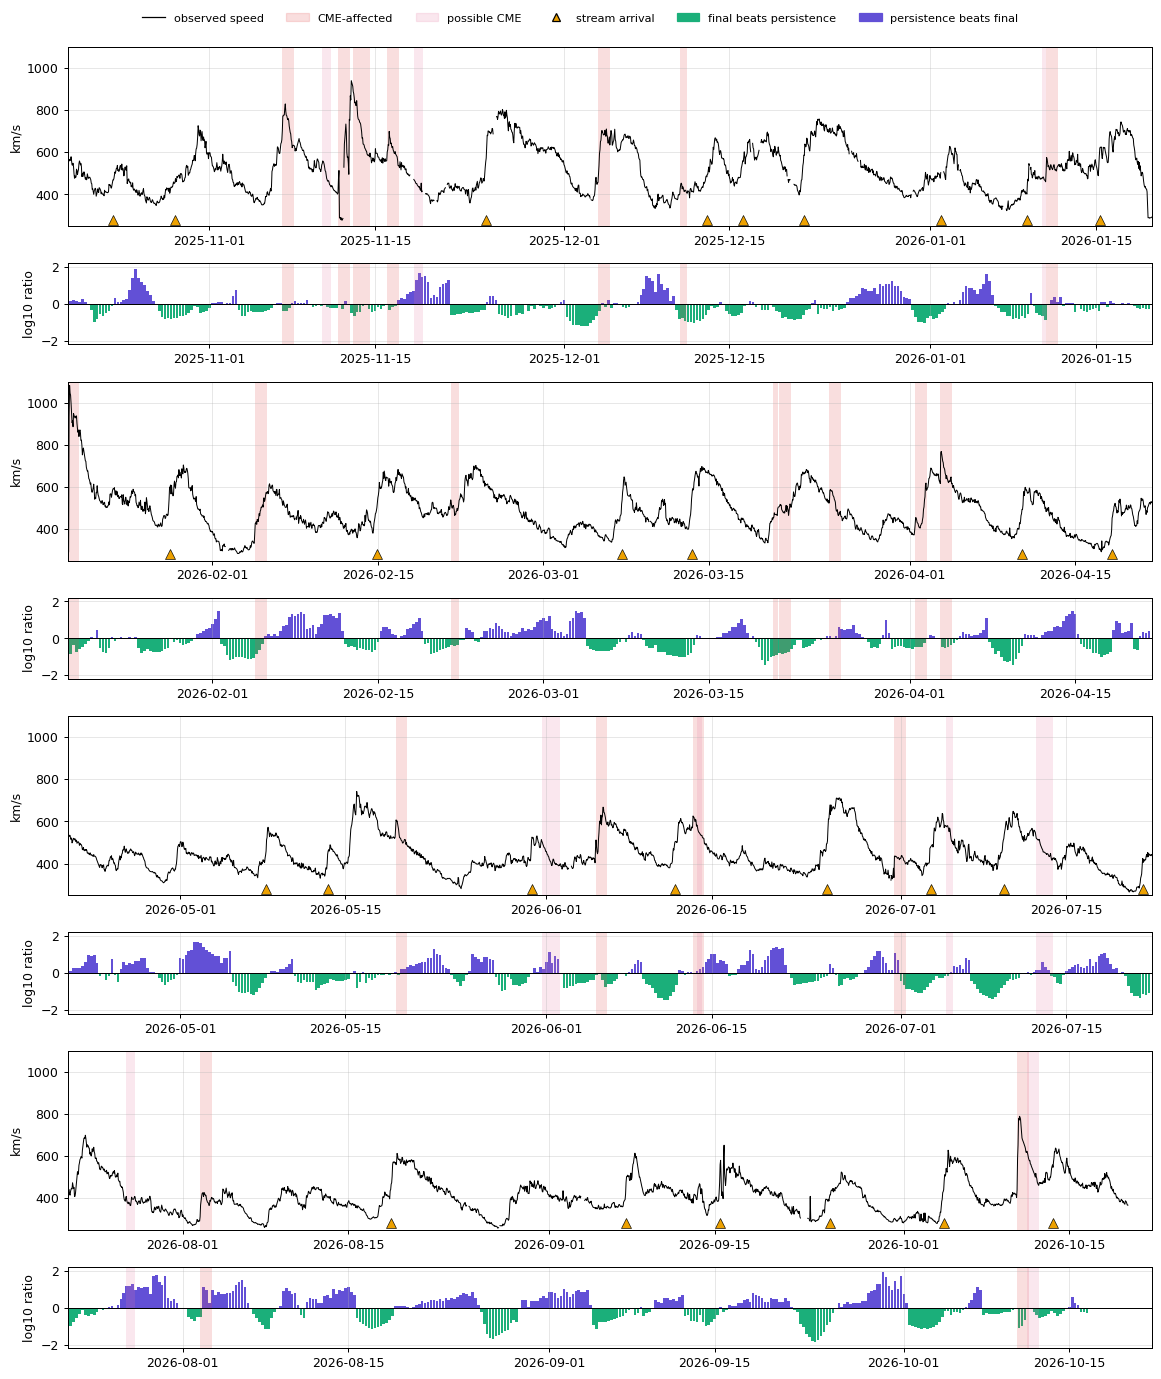

In [4]:
def shade(ax, lo, hi):
    for mask, span in ((cme, CME_SPAN), (possible, POSSIBLE_SPAN)):
        m = mask[(mask.index >= lo) & (mask.index < hi)]
        for s, e in ev._runs(m.to_numpy()):
            ax.axvspan(m.index[s], m.index[e - 1] + pd.Timedelta(hours=1), **span)


quarters = pd.date_range(TRAIN_END, EVAL_END + pd.Timedelta(days=2), periods=5)
fig, axes = plt.subplots(8, 1, figsize=(13, 15), gridspec_kw={"height_ratios": [2.2, 1] * 4})
log_ratio = np.log10(ratio)
for q in range(4):
    lo, hi = quarters[q], quarters[q + 1]
    ax_v, ax_r = axes[2 * q], axes[2 * q + 1]
    s = series[lo:hi]
    ax_v.plot(s.index, s, color="k", lw=0.8)
    shade(ax_v, lo, hi)
    for a in arrivals[(arrivals >= lo) & (arrivals < hi)]:
        ax_v.plot([a], [280], marker="^", color="#eda100",
                  ms=8, mec="k", mew=0.5)
    ax_v.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
    r = log_ratio[(log_ratio.index >= lo) & (log_ratio.index < hi)]
    ax_r.bar(r.index, r, width=0.22, color=np.where(r < 0, "#1baf7a", "#6250d6"))
    ax_r.axhline(0, color="k", lw=0.8)
    shade(ax_r, lo, hi)
    ax_r.set(ylabel="log10 ratio", xlim=(lo, hi), ylim=(-2.2, 2.2))
fig.tight_layout()
fig.legend(
    [Line2D([], [], color="k", lw=1), Patch(**{k: v for k, v in CME_SPAN.items() if k != "lw"}),
     Patch(**{k: v for k, v in POSSIBLE_SPAN.items() if k != "lw"}),
     Line2D([], [], ls="", marker="^", color="#eda100", mec="k"),
     Patch(color="#1baf7a"), Patch(color="#6250d6")],
    ["observed speed", "CME-affected", "possible CME", "stream arrival",
     "final beats persistence", "persistence beats final"],
    loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, frameon=False, fontsize=9,
);

### 1.1 Cross-check with the SOHO/LASCO CME catalogue

The in-situ detection above can miss CMEs. As an independent check, the SOHO/LASCO CME catalogue
(CDAW, pulled by `python -m training.pull_lasco_cme`) lists every CME seen leaving the Sun. Full-halo
CMEs (360° wide) are the ones that may be heading for Earth. For each, an arrival time at 1 AU is
estimated from its speed with the Gopalswamy et al. (2001) model, which is typically ±10–20 h out.

**Two flags:**
- **Fast halo** (main): a full halo of at least 800 km/s, not rated "very poor". Its window runs from 24 h before the estimated arrival to 48 h after, which allows for the timing error and about a day of CME passage.
- **Any halo** (stricter): every full halo that isn't rated "very poor", same window.

**Limits:**
- A halo can come from the far side of the Sun, so a flag means "a CME may have arrived", not "one did".
- The catalogue is published months late. It covers launches through July 2026, so runs reaching into August 2026 or later are "not covered".
- It is used here for analysis only; it was not available at forecast time.

In [5]:
from training import pull_lasco_cme as lasco

catalogue = lasco.load()
manifest = json.loads((lasco.OUT_DIR / "manifest.json").read_text())
covered_until = (pd.Period(manifest["months"][-1], "M") + 1).to_timestamp().tz_localize("UTC")
usable = (catalogue["halo"] & (catalogue["quality"] != "very poor")
          & catalogue["est_arrival"].notna())
halos = {"fast halo": catalogue[usable & (catalogue["linear_speed"] >= 800)],
         "any halo": catalogue[usable]}


BEFORE, AFTER = pd.Timedelta(hours=24), pd.Timedelta(hours=48)  # window around each arrival


def arrival_mask(index, cmes):
    mask = np.zeros(len(index), dtype=bool)
    for t in cmes["est_arrival"]:
        mask |= (index >= t - BEFORE) & (index < t + AFTER)
    return pd.Series(mask, index=index)


lasco_hours = {k: arrival_mask(series.index, v) for k, v in halos.items()}
covered = pd.Series(t0s + pd.Timedelta(hours=HORIZON + 1) <= covered_until, index=t0s)

# How well do the two independent views agree? (in-situ events inside the catalogue's coverage)
window = pd.Timedelta(hours=24)
insitu = events[(events["start"] >= TRAIN_END) & (events["start"] < covered_until)]
fast = halos["fast halo"]
fast_eval = fast[(fast["est_arrival"] >= TRAIN_END) & (fast["est_arrival"] < covered_until)]
agree = pd.DataFrame({
    kind: {
        "in-situ events": len(d),
        "with a fast halo within 24 h": int(sum(
            ((fast["est_arrival"] - t).abs() <= window).any() for t in d["start"])),
    }
    for kind, d in insitu.groupby("kind")
}).T
followed = sum(((insitu["start"] - t).abs() <= window).any() for t in fast_eval["est_arrival"])
rate = len(fast_eval) / ((covered_until - TRAIN_END) / pd.Timedelta(days=1))
print(f"catalogue covers launches through {manifest['months'][-1]}; "
      f"{covered.mean():.0%} of eval runs are covered")
print(f"fast halos arriving in the covered eval period: {len(fast_eval)}; "
      f"followed by an in-situ event within 24 h: {followed}")
print(f"chance of a fast halo falling within +-24 h of a random time: "
      f"{1 - np.exp(-2 * rate):.0%}")
agree

catalogue covers launches through 2026-07; 78% of eval runs are covered
fast halos arriving in the covered eval period: 29; followed by an in-situ event within 24 h: 12
chance of a fast halo falling within +-24 h of a random time: 18%


,in-situ events,with a fast halo within 24 h
ICME,5,3
possible ICME,8,1
shock only,14,8


## 2. Performance by regime

Each run is labelled by what happened during its 72 target hours (`ev.classify_runs`), in this
order of precedence:

| Regime | Rule |
|---|---|
| CME | any target hour CME-affected |
| possible CME | any target hour in a possible ICME |
| stream arrival | a non-CME high-speed stream arrives |
| fast stream | mean observed speed ≥ 550 km/s, no arrival |
| slow wind | maximum observed speed < 450 km/s |
| intermediate | everything else |

The last four are the **no-CME** regimes.

For each regime the table gives:
- **runs:** how many runs, and their share of the year;
- **share of the final baseline's per-run total:** where its error comes from;
- **per-run mean and median:** the final baseline's per-run TIMSE;
- **median ratio:** the final baseline's per-run TIMSE over persistence's, and over rolling recurrence's;
- **win rates:** how often the final baseline beats each.

In [6]:
cme_hours = cme.reindex(series.index, fill_value=False)
possible_hours = possible.reindex(series.index, fill_value=False)
regime = pd.Series(ev.classify_runs(t0s, actual, cme_hours, arrivals, possible_hours),
                   index=t0s, name="regime")
no_cme = regime.isin(ev.NO_CME).to_numpy()

rows = {}
for r in ev.REGIMES:
    sel = (regime == r).to_numpy()
    f = run_scores.loc[sel, "final_baseline"]
    p = run_scores.loc[sel, "persistence"]
    rc = run_scores.loc[sel, "recurrence_27d_rolling"]
    rows[r] = {
        "runs": int(sel.sum()),
        "share of runs": sel.mean(),
        "share of final's total": f.sum() / run_scores["final_baseline"].sum(),
        "final mean": f.mean(),
        "final median": f.median(),
        "median ratio vs persistence": (f / p).median(),
        "median ratio vs recurrence": (f / rc).median(),
        "beats persistence": (f < p).mean(),
        "beats recurrence": (f < rc).mean(),
        "pooled TIMSE vs persistence": timse(actual[sel], forecasts["final_baseline"][sel])
        / timse(actual[sel], forecasts["persistence"][sel]),
    }
by_regime = pd.DataFrame(rows).T
sel = no_cme
by_regime.loc["all no-CME"] = {
    "runs": int(sel.sum()), "share of runs": sel.mean(),
    "share of final's total": run_scores["final_baseline"][sel].sum()
    / run_scores["final_baseline"].sum(),
    "final mean": run_scores["final_baseline"][sel].mean(),
    "final median": run_scores["final_baseline"][sel].median(),
    "median ratio vs persistence": ratio[sel].median(),
    "median ratio vs recurrence": ratio_rec[sel].median(),
    "beats persistence": (ratio[sel] < 1).mean(),
    "beats recurrence": (ratio_rec[sel] < 1).mean(),
    "pooled TIMSE vs persistence": timse(actual[sel], forecasts["final_baseline"][sel])
    / timse(actual[sel], forecasts["persistence"][sel]),
}
by_regime["runs"] = by_regime["runs"].astype(int)
fmt(by_regime)

,runs,share of runs,share of final's total,final mean,final median,median ratio vs persistence,median ratio vs recurrence,beats persistence,beats recurrence,pooled TIMSE vs persistence
CME,295,0.204,0.612,7.78e+06,1.21e+06,0.533,0.738,0.732,0.634,0.674
possible CME,81,0.0559,0.0149,6.88e+05,5.07e+05,0.954,2.1,0.531,0.321,0.384
stream arrival,304,0.21,0.176,2.17e+06,1.46e+06,0.226,0.493,0.901,0.845,0.32
fast stream,105,0.0725,0.0405,1.45e+06,8.2e+05,0.648,0.482,0.705,0.714,0.712
slow wind,186,0.128,0.0449,9.06e+05,6.98e+05,6.63,3.62,0.043,0.0215,4.77
intermediate,477,0.329,0.112,8.81e+05,6.51e+05,1.64,2.76,0.325,0.239,0.67
all no-CME,1072,0.74,0.374,1.31e+06,8.07e+05,1.1,1.61,0.477,0.42,0.452


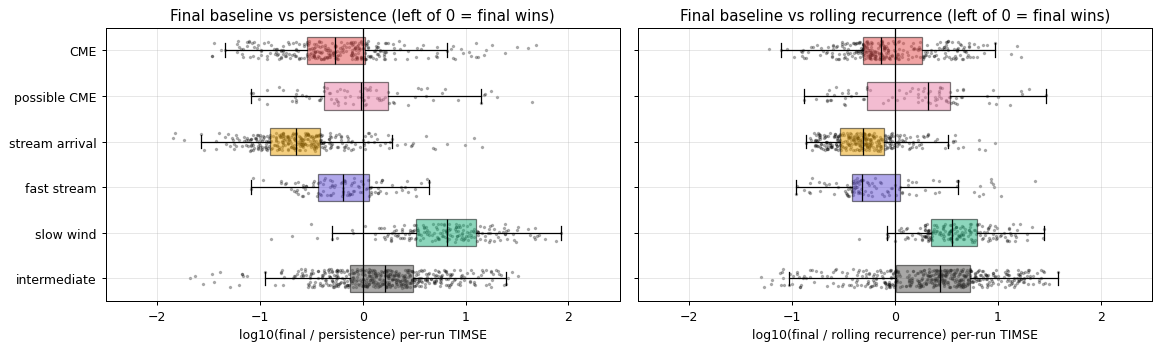

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = ev.REGIMES
for ax, (r, label) in zip(axes, [(ratio, "persistence"), (ratio_rec, "rolling recurrence")],
                          strict=True):
    data = [np.log10(r[(regime == g).to_numpy()].dropna()) for g in order]
    parts = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True,
                       widths=0.6, medianprops={"color": "k"})
    ax.set_yticks(range(1, len(order) + 1), order)
    for patch, g in zip(parts["boxes"], order, strict=True):
        patch.set(facecolor=REGIME_COLORS[g], alpha=0.5)
    rng = np.random.default_rng(0)
    for i, d in enumerate(data, 1):
        ax.scatter(d, i + rng.uniform(-0.2, 0.2, len(d)), s=3, color="k", alpha=0.25)
    ax.axvline(0, color="k", lw=1)
    ax.set(xlabel=f"log10(final / {label}) per-run TIMSE", xlim=(-2.5, 2.5),
           title=f"Final baseline vs {label} (left of 0 = final wins)")
axes[0].invert_yaxis()
fig.tight_layout()

### 2.1 Is the no-CME set clean?

Some no-CME runs may still contain a CME that the in-situ detection missed. This table repeats the
no-CME comparison on the runs the LASCO catalogue covers, split by whether a halo CME was due to
arrive during the run. It reports the median ratio vs persistence and the share of runs the final
baseline wins. If the no-CME failures came from hidden CMEs, the runs without a halo would look much
better.

In [8]:
def flagged(mask):
    hits = mask.to_numpy()[pos[:, None] + lead_all[None, :]]
    return pd.Series(hits.any(axis=1), index=t0s)


lead_all = np.arange(1, HORIZON + 1)
flags = {k: flagged(m) for k, m in lasco_hours.items()}
rows = {}
for g in [*ev.NO_CME, "all no-CME"]:
    in_g = regime.isin(ev.NO_CME) if g == "all no-CME" else regime == g
    base = (in_g & covered).to_numpy()
    row = {"covered runs": int(base.sum())}
    for k, f in flags.items():
        hit = base & f.to_numpy()
        clean = base & ~f.to_numpy()
        row[f"{k}: flagged"] = int(hit.sum())
        row[f"{k}: median ratio, flagged"] = ratio[hit].median() if hit.any() else np.nan
        row[f"{k}: median ratio, clean"] = ratio[clean].median()
        row[f"{k}: beats persistence, clean"] = (ratio[clean] < 1).mean()
    rows[g] = row
clean_table = pd.DataFrame(rows).T
fmt(clean_table)

,covered runs,fast halo: flagged,"fast halo: median ratio, flagged","fast halo: median ratio, clean","fast halo: beats persistence, clean",any halo: flagged,"any halo: median ratio, flagged","any halo: median ratio, clean","any halo: beats persistence, clean"
stream arrival,239,78,0.354,0.216,0.901,96,0.32,0.226,0.902
fast stream,104,33,0.522,0.7,0.662,42,0.418,0.799,0.613
slow wind,95,12,1.07,8.48,0,16,4.38,8.44,0
intermediate,349,95,1.26,2.07,0.26,148,1.71,1.78,0.294
all no-CME,787,218,0.69,1.22,0.453,302,0.811,1.14,0.466


## 3. Where it fails without CMEs

### 3.1 Bias and level

Mean residual and RMSE by lead, one panel per no-CME regime. A negative residual means the model
over-predicted.

bias 6 h RMSE 6 h bias 24 h RMSE 24 h bias 72 h RMSE 72 h
stream arrival final_baseline            -9.44     46.1     -49.1       103     -14.3      80.7
               recurrence_27d_rolling      3.8     44.7      9.21      94.7      50.6       111
               persistence                9.81       46      46.3       107       144       172
fast stream    final_baseline             7.82     49.3      13.4      77.6      -133       158
               recurrence_27d_rolling     20.6     52.9      63.9      99.8      32.8      96.7
               persistence                9.77     52.5      20.6       101     -97.7       152
slow wind      final_baseline            -24.6     31.7     -97.8       108      -166       175
               recurrence_27d_rolling    -10.9     24.2     -32.7      56.9     -78.5       104
               persistence                -8.6     21.1     -24.3        44     -34.1      70.3
intermediate   final_baseline            -17.5     35.1     -74.8      90.1      -159       174
               recurrence_27d_rolling    -4.19     30.6     -17.2      56.4     -41.5      94.9
               persistence               -6.18       32     -30.9        68     -73.4       126

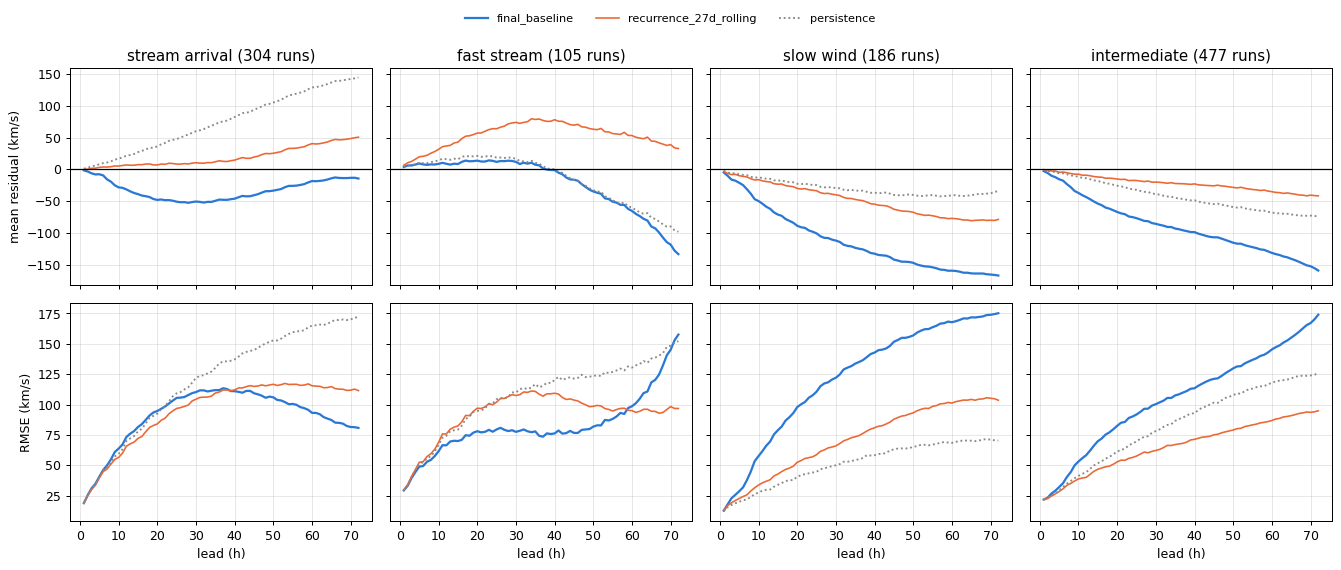

In [9]:
lead = np.arange(1, HORIZON + 1)
regimes = ev.NO_CME
fig, axes = plt.subplots(2, len(regimes), figsize=(15, 6), sharex=True, sharey="row")
bias_rows = {}
for col, g in enumerate(regimes):
    sel = (regime == g).to_numpy()
    for m in MODELS:
        r = residuals[m][sel]
        axes[0, col].plot(lead, np.nanmean(r, axis=0), **STYLE[m])
        axes[1, col].plot(lead, np.sqrt(np.nanmean(r**2, axis=0)), **STYLE[m])
        for k in (6, 24, 72):
            bias_rows[(g, m)] = bias_rows.get((g, m), {}) | {
                f"bias {k} h": np.nanmean(r[:, k - 1]),
                f"RMSE {k} h": np.sqrt(np.nanmean(r[:, k - 1] ** 2)),
            }
    axes[0, col].axhline(0, color="k", lw=1)
    axes[0, col].set_title(f"{g} ({sel.sum()} runs)")
    axes[1, col].set_xlabel("lead (h)")
axes[0, 0].set_ylabel("mean residual (km/s)")
axes[1, 0].set_ylabel("RMSE (km/s)")
fig.tight_layout()
model_legend(fig)
fmt(pd.DataFrame(bias_rows).T)

**What the tail-weighted loss costs on quiet runs.** For the final baseline, the table splits each
no-CME regime's per-run TIMSE into the part from over-prediction (forecast above the observation)
and the part from under-prediction. It also shows how far its mean forecast sits above the mean
observed speed, run by run. Per-run TIMSE weights depend only on the observations, so the split is
exact.

In [10]:
q = run_timse_weights(actual)
rows = {}
for g in regimes:
    sel = (regime == g).to_numpy()
    e = residuals["final_baseline"][sel]
    w = q[sel]
    contrib = np.where(np.isfinite(e), w * e**2, 0.0)
    over = np.where(e < 0, contrib, 0.0).sum() / contrib.sum()
    offset = np.nanmean(forecasts["final_baseline"][sel], axis=1) - np.nanmean(actual[sel], axis=1)
    rows[g] = {
        "share of TIMSE from over-prediction": over,
        "median (mean forecast - mean observed), km/s": np.median(offset),
        "runs over-predicted on average": (offset > 0).mean(),
        "median observed speed": np.nanmedian(actual[sel]),
    }
fmt(pd.DataFrame(rows).T)

,share of TIMSE from over-prediction,"median (mean forecast - mean observed), km/s",runs over-predicted on average,median observed speed
stream arrival,0.273,39.5,0.727,468
fast stream,0.246,21.5,0.705,616
slow wind,0.998,104,1,359
intermediate,0.918,86.7,0.981,439


**The forecast level has a floor.** The distribution of forecasts at 24 h and 72 h lead over all
runs, against the observed speeds (black). Under the per-run TIMSE loss, over-predicting a slow hour
costs little and under-predicting a fast one costs a lot, so the fitted model rarely forecasts slow
wind.

p1  p10 median  p90
24 h final_baseline          388  440    524  617
     recurrence_27d_rolling  323  375    465  575
     persistence             280  347    447  623
     observed                281  349    448  623
72 h final_baseline          447  502    567  655
     recurrence_27d_rolling  343  386    459  570
     persistence             280  347    447  623
     observed                281  349    448  623

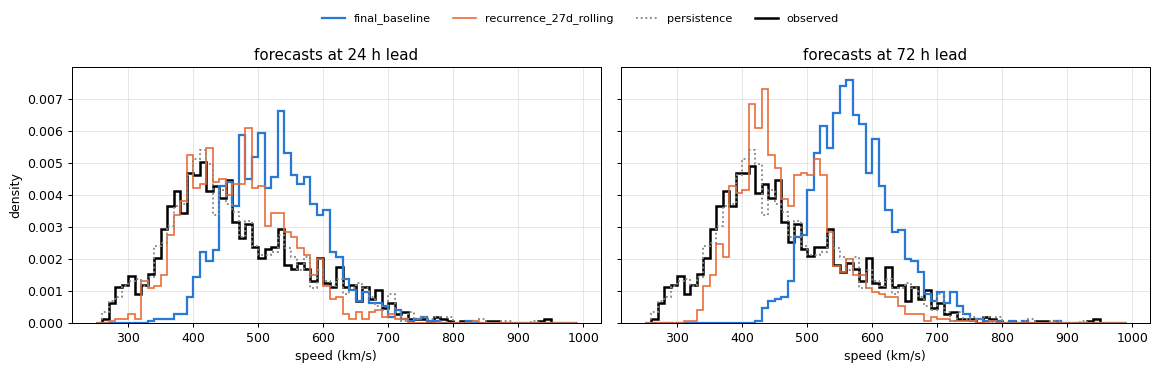

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
bins = np.arange(250, 1000, 10)
quant = {}
for ax, k in zip(axes, (24, 72), strict=True):
    ax.hist(actual[:, k - 1][np.isfinite(actual[:, k - 1])], bins=bins, histtype="step",
            color="k", lw=2, density=True)
    for m in MODELS:
        ax.hist(forecasts[m][:, k - 1], bins=bins, histtype="step", density=True, **STYLE[m])
        quant[(f"{k} h", m)] = np.quantile(forecasts[m][:, k - 1], [0.01, 0.1, 0.5, 0.9])
    quant[(f"{k} h", "observed")] = np.nanquantile(actual[:, k - 1], [0.01, 0.1, 0.5, 0.9])
    ax.set(title=f"forecasts at {k} h lead", xlabel="speed (km/s)")
axes[0].set_ylabel("density")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")])
fmt(pd.DataFrame(quant, index=["p1", "p10", "median", "p90"]).T)

### 3.2 Stream arrivals

A superposed-epoch view of the non-CME high-speed-stream arrivals: forecasts valid at each hour
around the arrival time (hour 0), made about 1, 2 or 3 days earlier, shown as the median over
arrivals. The black line is the median observed speed.

The table gives, for each lead group, the share of the observed speed rise that each model's
forecast reproduces: the mean over +12…+36 h minus the mean over −36…−12 h, forecast over observed,
median over arrivals.

29 non-CME stream arrivals


,final_baseline: share of rise,recurrence_27d_rolling: share of rise,persistence: share of rise
~1 day ahead (19-30 h),0.27,0.301,0.42
~2 days ahead (43-54 h),0.0355,0.139,-0.156
~3 days ahead (61-72 h),0.0236,0.18,-0.251


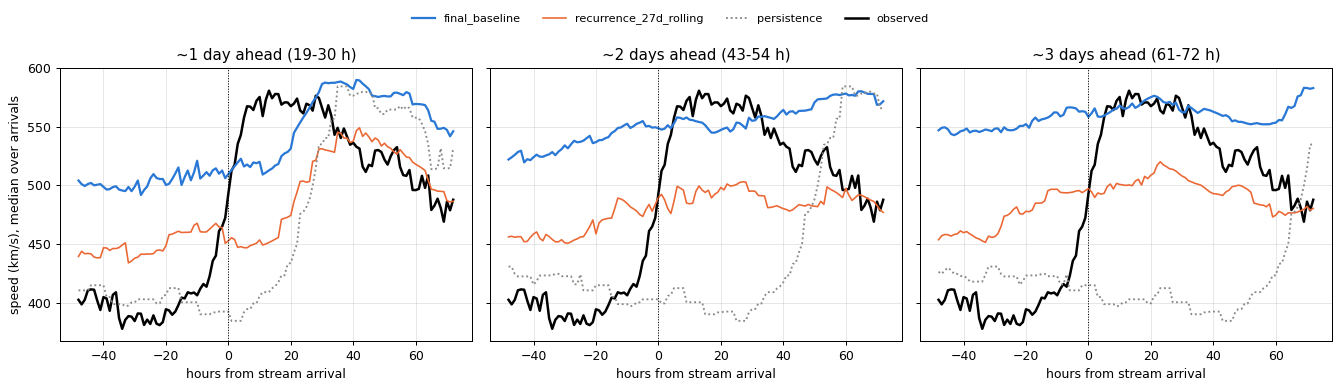

In [12]:
eval_arrivals = arrivals[(arrivals >= TRAIN_END + pd.Timedelta(days=3)) & (arrivals < EVAL_END)]
valid = t0s.values[:, None] + lead[None, :] * np.timedelta64(1, "h")
lead_grid = np.broadcast_to(lead, valid.shape)
groups = {"~1 day ahead (19-30 h)": (19, 30), "~2 days ahead (43-54 h)": (43, 54),
          "~3 days ahead (61-72 h)": (61, 72)}
rel_hours = np.arange(-48, 73)
epoch, capture = {}, {}
for gname, (lo, hi) in groups.items():
    stacks = {m: [] for m in MODELS}
    caps = {m: [] for m in MODELS}
    obs_stack = []
    for a in eval_arrivals:
        rel = (valid - a.tz_convert(None).to_datetime64()) / np.timedelta64(1, "h")
        sel = (rel >= -48) & (rel <= 72) & (lead_grid >= lo) & (lead_grid <= hi)
        obs = series.reindex(a + pd.to_timedelta(rel_hours, unit="h")).to_numpy()
        obs_stack.append(obs)
        rise_obs = np.nanmean(obs[(rel_hours >= 12) & (rel_hours <= 36)]) - np.nanmean(
            obs[(rel_hours >= -36) & (rel_hours <= -12)])
        for m in MODELS:
            df = pd.DataFrame({"rel": rel[sel].round().astype(int), "f": forecasts[m][sel]})
            curve = df.groupby("rel")["f"].mean().reindex(rel_hours)
            stacks[m].append(curve.to_numpy())
            after = curve[(curve.index >= 12) & (curve.index <= 36)].mean()
            before = curve[(curve.index >= -36) & (curve.index <= -12)].mean()
            caps[m].append((after - before) / rise_obs)
    epoch[gname] = ({m: np.nanmedian(np.array(stacks[m]), axis=0) for m in MODELS},
                    np.nanmedian(np.array(obs_stack), axis=0))
    capture[gname] = {m: np.nanmedian(caps[m]) for m in MODELS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (gname, (curves, obs)) in zip(axes, epoch.items(), strict=True):
    ax.plot(rel_hours, obs, color="k", lw=2)
    for m in MODELS:
        ax.plot(rel_hours, curves[m], **STYLE[m])
    ax.axvline(0, color="k", lw=0.8, ls=":")
    ax.set(title=gname, xlabel="hours from stream arrival")
axes[0].set_ylabel("speed (km/s), median over arrivals")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")])
print(f"{len(eval_arrivals)} non-CME stream arrivals")
fmt(pd.DataFrame(capture).T.rename(columns=lambda m: f"{m}: share of rise"))

### 3.3 When the previous rotation is a poor guide

The model leans on the speed one rotation (27 d) and half a rotation earlier. For each run,
**rotation mismatch** is the RMSE between the observed target hours and the speed observed exactly
27 days earlier. It is small when the coronal-hole pattern repeats and large when the streams have
changed. The no-CME runs are split into quartiles of mismatch.

Quiet runs vary little, so their mismatch is small too: the quartiles partly repeat the regime split.
The second table separates the two by splitting each regime at its own median mismatch.

**CME echoes** are no-CME runs whose 27-day lagged input (the 72 hours one rotation before the
target hours) contains CME-affected or possible-CME hours. In these runs the model is fed a transient
that won't recur. Runs are grouped by how many of those 72 lagged hours are affected.

,runs,mismatch_km_s,final_median,final_mean,median_ratio_vs_persistence,beats_persistence,median_ratio_vs_recurrence
mismatch quartile,,,,,,,
Q1 (repeats),268,43.2,5.27e+05,6.88e+05,1.76,0.269,4.06
Q2,268,66.4,7.04e+05,9.26e+05,1.27,0.466,1.98
Q3,268,89,7.6e+05,9.67e+05,0.729,0.582,0.836
Q4 (changed),268,162,1.78e+06,2.65e+06,0.576,0.59,0.889


runs mismatch_km_s final_median median_ratio_vs_persistence median_ratio_vs_recurrence
regime         mismatch half                                                                                               
stream arrival changed (upper half)   152           152     1.98e+06                       0.273                      0.603
               repeats (lower half)   152          73.5     1.01e+06                       0.183                      0.358
fast stream    changed (upper half)    52           168     1.36e+06                       0.787                      0.428
               repeats (lower half)    53          74.9     6.86e+05                       0.522                      0.648
slow wind      changed (upper half)    93            99     1.06e+06                        8.32                       2.73
               repeats (lower half)    93          53.4     5.13e+05                        5.42                       4.57
intermediate   changed (upper half)   238          87.8     7.59e+05                        1.27                       1.79
               repeats (lower half)   239          50.4      5.8e+05                        1.75                       4.45

,runs,final_median,final_mean,median_ratio_vs_persistence,beats_persistence
CME hours in the 27-day lagged input,,,,,
none,827,7.54e+05,1.32e+06,1.05,0.487
1-11 h,52,7.84e+05,1.17e+06,3.11,0.327
12+ h,193,1.12e+06,1.3e+06,1.21,0.472


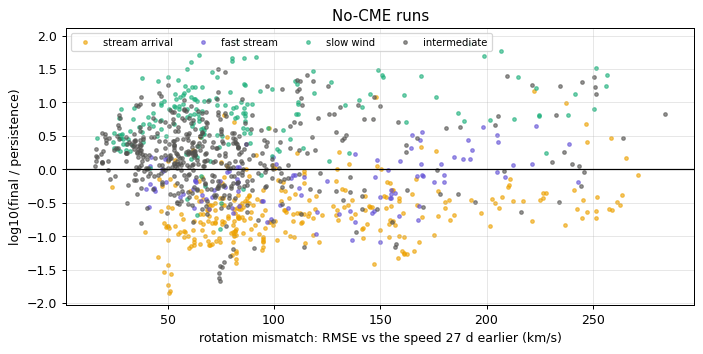

In [13]:
lag_idx = pos[:, None] + lead[None, :] - ROTATION
lagged = values[lag_idx]
mismatch = pd.Series(np.sqrt(np.nanmean((actual - lagged) ** 2, axis=1)), index=t0s)
any_cme = (cme_hours | possible_hours).to_numpy()
echo_hours = pd.Series(any_cme[lag_idx].sum(axis=1), index=t0s)
echo = pd.cut(echo_hours, [-1, 0, 11, HORIZON],
              labels=["none", "1-11 h", "12+ h"]).rename("CME hours in 27-d lag")

nc = pd.DataFrame({"mismatch": mismatch, "ratio": ratio, "ratio_rec": ratio_rec,
                   "final": run_scores["final_baseline"], "echo": echo, "regime": regime})[no_cme]
nc["mismatch quartile"] = pd.qcut(nc["mismatch"], 4, labels=["Q1 (repeats)", "Q2", "Q3",
                                                             "Q4 (changed)"])
summary = nc.groupby("mismatch quartile", observed=True).agg(
    runs=("final", "size"),
    mismatch_km_s=("mismatch", "median"),
    final_median=("final", "median"),
    final_mean=("final", "mean"),
    median_ratio_vs_persistence=("ratio", "median"),
    beats_persistence=("ratio", lambda r: (r < 1).mean()),
    median_ratio_vs_recurrence=("ratio_rec", "median"),
)
display(fmt(summary))
half = nc.groupby("regime", observed=True)["mismatch"].transform("median")
nc["mismatch half"] = np.where(nc["mismatch"] <= half, "repeats (lower half)",
                               "changed (upper half)")
within = nc.groupby(["regime", "mismatch half"], observed=True).agg(
    runs=("final", "size"),
    mismatch_km_s=("mismatch", "median"),
    final_median=("final", "median"),
    median_ratio_vs_persistence=("ratio", "median"),
    median_ratio_vs_recurrence=("ratio_rec", "median"),
)
display(fmt(within))
echo_table = nc.groupby("echo", observed=True).agg(
    runs=("final", "size"), final_median=("final", "median"), final_mean=("final", "mean"),
    median_ratio_vs_persistence=("ratio", "median"),
    beats_persistence=("ratio", lambda r: (r < 1).mean()),
)
echo_table.index.name = "CME hours in the 27-day lagged input"
display(fmt(echo_table))

fig, ax = plt.subplots(figsize=(9, 4))
for g in ev.NO_CME:
    d = nc[nc["regime"] == g]
    ax.scatter(d["mismatch"], np.log10(d["ratio"]), s=8, alpha=0.6, color=REGIME_COLORS[g],
               label=g)
ax.axhline(0, color="k", lw=1)
ax.set(xlabel="rotation mismatch: RMSE vs the speed 27 d earlier (km/s)",
       ylabel="log10(final / persistence)", title="No-CME runs")
ax.legend(fontsize=8, ncol=4, loc="upper left");

### 3.4 The worst no-CME runs

The ten no-CME runs with the highest per-run TIMSE for the final baseline (the ones that dominate its
total), and the ten where it loses most heavily to persistence.

In [14]:
cols = {"regime": regime, "final": run_scores["final_baseline"],
        "persistence": run_scores["persistence"],
        "recurrence": run_scores["recurrence_27d_rolling"], "ratio vs persistence": ratio,
        "peak observed": pd.Series(np.nanmax(actual, axis=1), index=t0s),
        "rotation mismatch": mismatch, "CME hours in lag": echo_hours,
        "fast halo due": flags["fast halo"].map({True: "yes", False: "no"})
        .where(covered, "not covered")}
table = pd.DataFrame(cols)[no_cme]
table.index = table.index.strftime("%Y-%m-%d %H")
print("Highest per-run TIMSE (final baseline):")
display(fmt(table.sort_values("final", ascending=False).head(10)))
print("Largest losses to persistence:")
display(fmt(table.sort_values("ratio vs persistence", ascending=False).head(10)))

Highest per-run TIMSE (final baseline):


,regime,final,persistence,recurrence,ratio vs persistence,peak observed,rotation mismatch,CME hours in lag,fast halo due
2025-11-23 00,stream arrival,1.66e+07,5.26e+07,2.29e+07,0.315,804,204,0,yes
2025-11-23 06,stream arrival,1.49e+07,4.48e+07,2.28e+07,0.333,804,217,0,yes
2025-11-23 12,stream arrival,1.39e+07,3.94e+07,2.27e+07,0.353,804,225,0,yes
2025-11-22 18,stream arrival,1.38e+07,4.01e+07,2.01e+07,0.345,796,182,0,yes
2025-11-23 18,stream arrival,1.31e+07,3.58e+07,2.17e+07,0.366,804,227,0,yes
2025-11-24 00,stream arrival,1.13e+07,2.54e+07,2.02e+07,0.443,804,228,0,yes
2025-11-22 12,stream arrival,1.07e+07,3.23e+07,1.72e+07,0.331,795,159,0,yes
2026-06-23 00,stream arrival,1.07e+07,3.6e+07,1.91e+07,0.297,712,167,0,no
2026-05-15 06,fast stream,1.07e+07,2.19e+07,1.95e+07,0.488,743,155,0,no
2025-11-24 06,stream arrival,1.06e+07,2.43e+07,1.83e+07,0.435,804,227,0,yes


Largest losses to persistence:


,regime,final,persistence,recurrence,ratio vs persistence,peak observed,rotation mismatch,CME hours in lag,fast halo due
2026-09-29 06,slow wind,8.45e+05,1.01e+04,3.73e+05,84,337,82.7,0,not covered
2025-10-25 18,slow wind,2.87e+06,3.82e+04,2.87e+06,75.1,435,192,0,yes
2026-07-29 18,slow wind,1.64e+06,2.78e+04,8.88e+05,59.2,367,207,14,not covered
2026-09-30 18,slow wind,6.34e+05,1.23e+04,1.76e+05,51.6,337,64.8,0,not covered
2026-07-29 12,slow wind,1.47e+06,2.97e+04,7.66e+05,49.3,367,199,14,not covered
2026-05-02 06,slow wind,4.58e+05,9.6e+03,3.57e+04,47.7,445,91.6,0,no
2026-05-02 12,slow wind,4.4e+05,9.39e+03,4.57e+04,46.9,445,86,0,no
2026-09-29 12,slow wind,8.33e+05,1.81e+04,3.78e+05,45.9,337,80.1,0,not covered
2026-05-02 18,slow wind,4.81e+05,1.14e+04,6.33e+04,42.3,445,80.4,0,no
2026-01-05 18,slow wind,1.85e+06,4.53e+04,3.83e+05,40.8,417,61.2,13,no


Four examples:
- the worst run by TIMSE among stream arrivals;
- the worst among fast streams;
- the heaviest loss to persistence in slow wind;
- the heaviest loss to persistence among intermediate runs.

Each panel shows:
- the 48 h before `t0`, then the 72 h forecast;
- the observed speed (black);
- the speed observed 27 days earlier (grey dashed), the main input to the recurrence term.

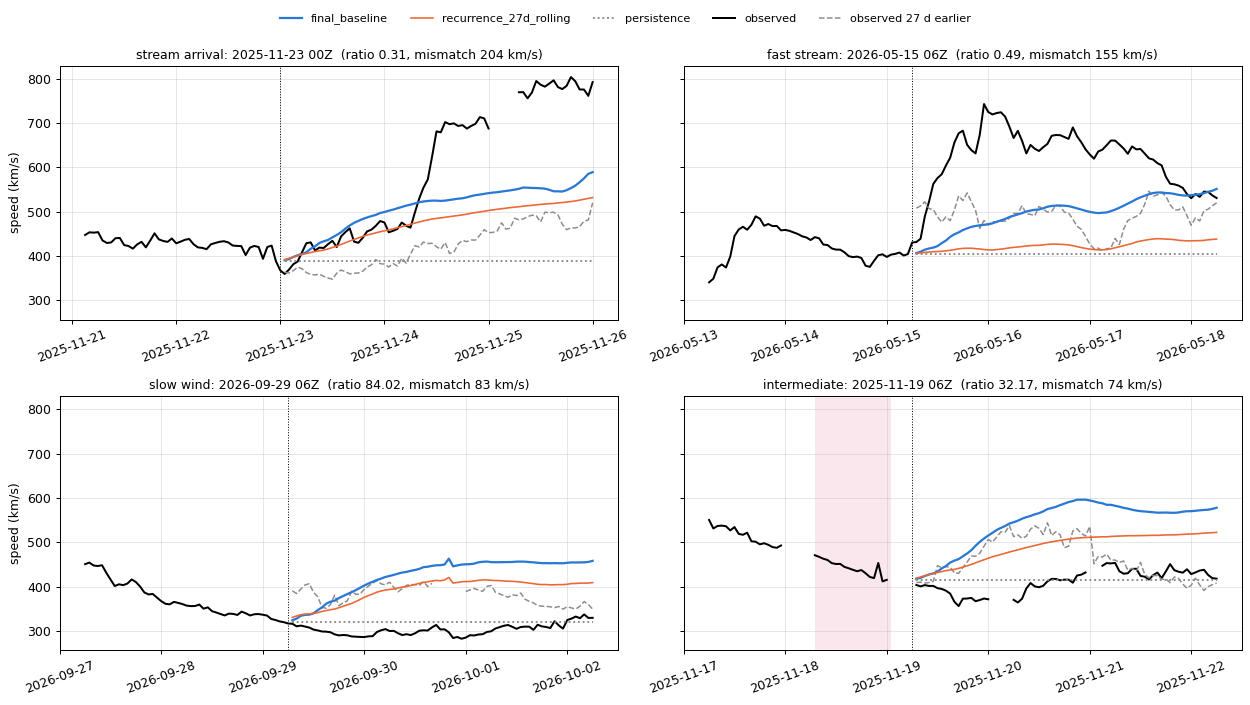

In [15]:
picks = []
for g, key in [("stream arrival", "final"), ("fast stream", "final"),
               ("slow wind", "ratio vs persistence"), ("intermediate", "ratio vs persistence")]:
    d = pd.DataFrame(cols)[(regime == g).to_numpy()]
    if len(d):
        picks.append((g, key, d[key].idxmax()))

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharey=True)
for ax, (g, _key, t0) in zip(axes.flat, picks, strict=False):
    i = t0s.get_loc(t0)
    hist = series[t0 - pd.Timedelta(hours=48): t0 + pd.Timedelta(hours=HORIZON)]
    ax.plot(hist.index, hist, color="k", lw=1.6)
    times = t0 + pd.to_timedelta(lead, unit="h")
    ax.plot(times, lagged[i], color="0.55", lw=1.2, ls="--")
    for m in MODELS:
        ax.plot(times, forecasts[m][i], **STYLE[m])
    ax.axvline(t0, color="k", lw=0.8, ls=":")
    shade(ax, hist.index[0], hist.index[-1])
    ax.set_title(f"{g}: {t0:%Y-%m-%d %H}Z  (ratio {ratio.iloc[i]:.2f}, "
                 f"mismatch {mismatch.iloc[i]:.0f} km/s)", fontsize=10)
    ax.tick_params(axis="x", labelrotation=20)
for ax in axes[:, 0]:
    ax.set_ylabel("speed (km/s)")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.6), "observed"),
                   (Line2D([], [], color="0.55", lw=1.2, ls="--"), "observed 27 d earlier")])

## 4. Findings

Eval year 2025-10-20 → 2026-10-20, 1,448 runs. Overall the final baseline beats persistence in 53%
of runs and rolling recurrence in 46%. It still has by far the best per-run mean (2.59 × 10⁶, against
5.57 × 10⁶ for persistence) and pooled TIMSE. Its wins and losses split cleanly by solar-wind regime.

### (i) Where it does well: anything fast

| Regime | share of runs | share of its per-run total | median ratio vs persistence | beats persistence | beats recurrence |
|---|---|---|---|---|---|
| CME | 20% | 61% | 0.53 | 73% | 63% |
| stream arrival (no CME) | 21% | 18% | **0.23** | **90%** | **85%** |
| fast stream (no CME) | 7% | 4% | 0.65 | 71% | 71% |

- **Fast wind is where TIMSE is decided**, and the model wins there.
  - CME and stream-arrival runs are 41% of runs but 79% of the model's per-run total.
  - In those runs it cuts persistence's error by half to three-quarters.
- **CMEs still dominate the error.** CME runs are a fifth of the year but 61% of the model's per-run total. A speed-history model can't see a CME coming; it wins there only by already forecasting high.

### (ii) Where it fails: quiet wind with no CME

| Regime | share of runs | share of its per-run total | median ratio vs persistence | beats persistence | beats recurrence |
|---|---|---|---|---|---|
| slow wind (peak < 450 km/s) | 13% | 4% | **6.6** | **4%** | **2%** |
| intermediate | 33% | 11% | 1.6 | 33% | 24% |
| all no-CME | 74% | 37% | 1.10 | 48% | 42% |

- **In quiet wind the model loses almost every run.**
  - In slow wind it beats persistence in 4% of runs and rolling recurrence in 2%. Its typical run scores 6.6× persistence's.
  - Over the whole slow-wind set its pooled TIMSE is 4.8× persistence's.
  - Intermediate runs, a third of the year, go the same way, less severely.
- **Hidden CMEs don't explain it** (section 2.1).
  - Among the runs the LASCO catalogue covers, the runs with no fast halo CME due are the cleanest no-CME set. On those, slow wind scores a median 8.5× persistence and the final baseline wins none of them; intermediate runs score 2.1× and win 26%.
  - Runs with a halo due look better for the final baseline (slow wind 1.1×, intermediate 1.3×), because a CME that does arrive speeds the wind up towards the level the model forecasts anyway.
  - The quiet-wind failure is a property of the model in ambient wind, not of mislabelled CMEs.
- **The cause is one systematic over-prediction, not noise** (section 3.1).
  - The mean forecast sits a median 104 km/s above the observed mean in slow-wind runs, and 87 km/s above it in intermediate runs.
  - Every slow-wind run is over-predicted on average. Over-prediction makes up 99.8% of the slow-wind TIMSE and 92% of the intermediate TIMSE.
  - The bias grows with lead, to −166 km/s at 72 h in slow wind. Its RMSE there is 175 km/s, against 70 km/s for persistence.
- **The forecast level has a floor.**
  - At 72 h the model almost never forecasts below 450 km/s: the 1st percentile is 447 km/s, the median 567.
  - The observed median is 448 km/s, and 10% of hours are below 349 km/s.
  - This is the per-run TIMSE loss working as designed. Over-predicting a slow hour is cheap and under-predicting a fast one is expensive, so the fit hedges high everywhere. The quiet runs cost little in total (15% of the per-run total from 46% of the runs), so the per-run mean barely notices.
  - **Any leaderboard that looks at the typical run (a median, a rank, a win rate) would punish this heavily.**

### (iii) Stream arrivals are caught by level, not by timing

- **Over 29 CME-free stream arrivals, the model shows almost no arrival signal beyond a day** (section 3.2).
  - Forecasts made 2–3 days ahead reproduce 2–4% of the observed rise; rolling recurrence manages 14–18%.
  - At 2–3 days the model sits flat at about 550 km/s on both sides of the arrival.
- **It wins arrival runs because it is already high when the stream comes,** not because it predicts the stream. Before the arrival it over-predicts by about 50 km/s at 24 h lead.
- **About a day ahead it captures 27% of the rise,** close to persistence (42%) and rolling recurrence (30%). It is mostly following the stream once it has started.
- **The heaviest no-CME runs are arrivals of a stream faster than the one a rotation earlier.** On 22–24 November 2025 the speed reached about 800 km/s, with a rotation mismatch above 200 km/s. The model under-forecasts by about 250 km/s there, though it still beats persistence.

### (iv) Recurrence: what helps and what hurts

- **The model under-uses a good recurrence signal in quiet wind** (section 3.3).
  - When the previous rotation repeats (lower half of rotation mismatch), rolling recurrence beats the final baseline by 4.6× in slow wind and 4.5× in intermediate runs.
  - When the rotation has changed, the gap shrinks to 2.7× and 1.8×.
  - The floor stops the final baseline following a recurrence signal that says "slow".
- **In stream regimes, a repeating rotation helps it as expected.** Its median ratio vs persistence is 0.18 when the rotation repeats and 0.27 when it has changed.
- **CMEs one rotation earlier contaminate the recurrence input.**
  - 193 no-CME runs (18%) have at least 12 CME-affected hours in their 27-day lagged input.
  - Their median per-run TIMSE is 49% higher (1.12 × 10⁶ against 7.5 × 10⁵), and their median ratio vs persistence is 1.21 against 1.05.

### What this means for the next model

1. **Make the level conditional, not constant.**
   - The biggest no-CME gain is to stop forecasting fast wind when none is coming. Signals that could say "no stream expected": a coronal hole at central meridian, low recent variability, recurrence agreeing on slow wind.
   - The baseline's loss rewards a constant hedge because it has no information about when a stream is coming.
2. **Mask transients in the recurrence input.** Replace CME-affected hours one rotation back with an ambient estimate. This is cheap, and 18% of no-CME runs are affected.
3. **Timing beyond a day needs solar inputs.** Speed history alone gives no arrival signal at 2–3 days. Coronal-hole maps or WSA/ENLIL-type predictions are the obvious next inputs.
4. **Settle the aggregation question.** Under the per-run mean the hedge is rational. Under a median-, rank- or win-rate-based leaderboard it would be a liability. The model should be re-tuned once Benchlab confirms how runs are combined.

### Caveats

- **CME identification:** the regimes come from CMEs identified in the real-time data itself; the event catalogues (NASA DONKI, Richardson & Cane) were unreachable.
  - The criteria are standard, and runs with weak-field cold intervals ("possible CME", 81 runs) are kept out of the no-CME set.
  - Some CMEs may still be missed, and some "shock only" passages may be stream-driven.
- **LASCO cross-check (section 1.1):**
  - **Agreement:** fast halo CMEs agree with the in-situ events well beyond chance. 3 of 5 ICMEs and 8 of 14 shocks have a fast halo arriving within 24 h, against an 18% chance rate.
  - **Not a ground truth:** the catalogue can't tell Earth-directed halos from far-side ones, the arrival model is ±10–20 h, and it covers launches only through July 2026 (78% of eval runs).
- **Real-time data artefacts:** the data has known artefacts in large events (the frozen 290 km/s before the January 2026 shock). The scoring uses the same series, as the live leaderboard does.
- **One year:** these are eval-year results, from one year near solar maximum.